In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Connect to the existing SQLite data warehouse
db_path = Path("../04_Data_Warehouse/breast_cancer_warehouse.db")

conn = sqlite3.connect(db_path)

# Load data from the warehouse
query = """
SELECT
    f.Fact_Key,
    f.Patient_Count,
    d.Class,
    t.Tumor_Size,
    t.Inv_Nodes,
    t.Deg_Malig,
    t.Node_Caps,
    c.Irradiat,
    p.Age,
    p.Breast
FROM Fact_Breast_Cancer f
JOIN Dim_Diagnosis d
    ON f.Diagnosis_Key = d.Diagnosis_Key
JOIN Dim_Tumor t
    ON f.Tumor_Key = t.Tumor_Key
JOIN Dim_Clinical c
    ON f.Clinical_Key = c.Clinical_Key
JOIN Dim_Patient p
    ON f.Patient_Key = p.Patient_Key
"""

dashboard_df = pd.read_sql_query(query, conn)

print("DASHBOARD DATA LOADED")
print("Dataset shape:", dashboard_df.shape)
print("\nFirst five records:")
display(dashboard_df.head())

print("\nDiagnosis class counts:")
print(dashboard_df["Class"].value_counts().sort_index())

print("\nMissing values:", dashboard_df.isnull().sum().sum())

conn.close()

DASHBOARD DATA LOADED
Dataset shape: (272, 10)

First five records:


,Fact_Key,Patient_Count,Class,Tumor_Size,Inv_Nodes,Deg_Malig,Node_Caps,Irradiat,Age,Breast
0,1,1,0,32.0,1.0,3,0,0,34.5,0
1,2,1,0,22.0,1.0,2,0,0,44.5,1
2,3,1,0,22.0,1.0,2,0,0,44.5,0
3,4,1,0,17.0,1.0,2,0,0,64.5,1
4,5,1,0,2.0,1.0,2,0,0,44.5,1



Diagnosis class counts:
Class
0    191
1     81
Name: count, dtype: int64

Missing values: 0


===== BREAST CANCER DASHBOARD SUMMARY =====
Total Records: 272
Class 0 Records: 191
Class 1 Records: 81
Average Tumor Size: 26.60
Average Involved Nodes: 2.63


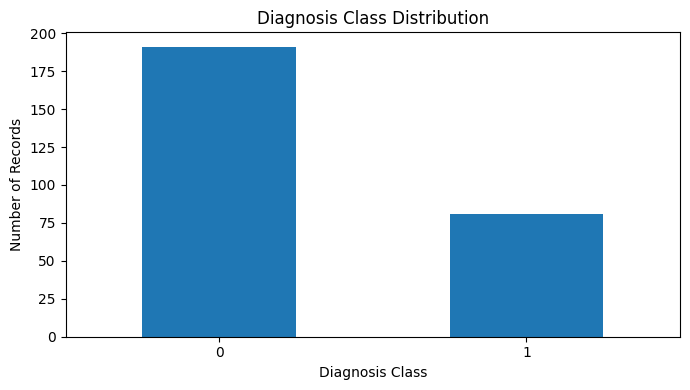

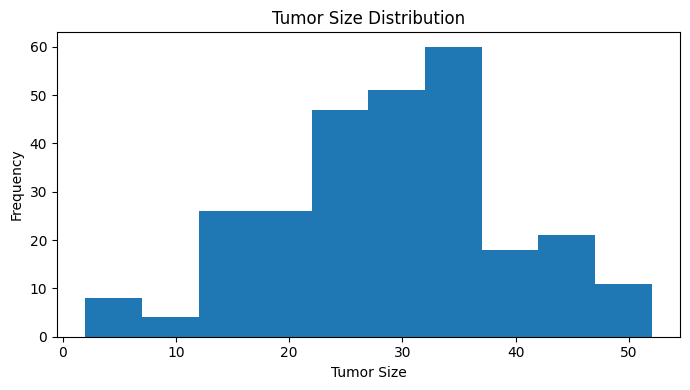

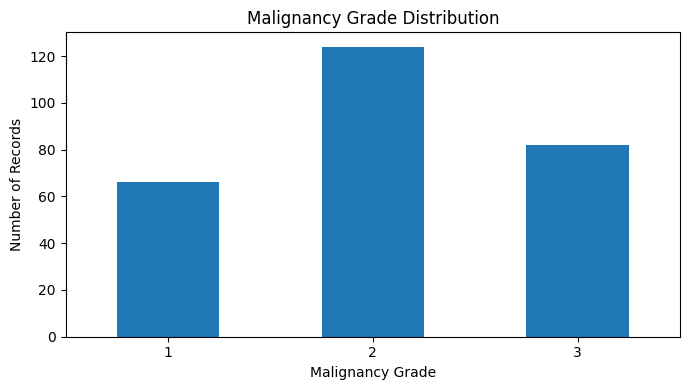

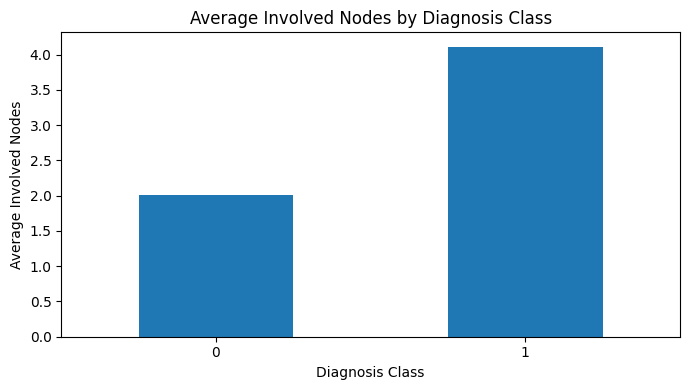

In [3]:
# Step 10.2: Dashboard Summary Metrics and Charts

# 1. Summary metrics
total_records = len(dashboard_df)
class_0_count = (dashboard_df["Class"] == 0).sum()
class_1_count = (dashboard_df["Class"] == 1).sum()
avg_tumor_size = dashboard_df["Tumor_Size"].mean()
avg_inv_nodes = dashboard_df["Inv_Nodes"].mean()

print("===== BREAST CANCER DASHBOARD SUMMARY =====")
print("Total Records:", total_records)
print("Class 0 Records:", class_0_count)
print("Class 1 Records:", class_1_count)
print(f"Average Tumor Size: {avg_tumor_size:.2f}")
print(f"Average Involved Nodes: {avg_inv_nodes:.2f}")

# 2. Diagnosis class distribution
class_counts = dashboard_df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
class_counts.plot(kind="bar")
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Tumor size distribution
plt.figure(figsize=(7, 4))
plt.hist(dashboard_df["Tumor_Size"], bins=10)
plt.title("Tumor Size Distribution")
plt.xlabel("Tumor Size")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 4. Malignancy grade distribution
malig_counts = dashboard_df["Deg_Malig"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
malig_counts.plot(kind="bar")
plt.title("Malignancy Grade Distribution")
plt.xlabel("Malignancy Grade")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 5. Average involved lymph nodes by diagnosis class
avg_nodes_by_class = dashboard_df.groupby("Class")["Inv_Nodes"].mean()

plt.figure(figsize=(7, 4))
avg_nodes_by_class.plot(kind="bar")
plt.title("Average Involved Nodes by Diagnosis Class")
plt.xlabel("Diagnosis Class")
plt.ylabel("Average Involved Nodes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:

# Step 10.3: Interactive Dashboard Filters

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path

# 1. Load data if dashboard_df is not already available
if "dashboard_df" not in globals():
    db_path = Path("../04_Data_Warehouse/breast_cancer_warehouse.db")

    if not db_path.exists():
        raise FileNotFoundError(
            f"Database not found: {db_path.resolve()}. "
            "Check the notebook location."
        )

    with sqlite3.connect(db_path) as conn:
        query = """
        SELECT
            f.Fact_Key,
            f.Patient_Count,
            d.Class,
            t.Tumor_Size,
            t.Inv_Nodes,
            t.Deg_Malig,
            t.Node_Caps,
            c.Irradiat,
            p.Age,
            p.Breast
        FROM Fact_Breast_Cancer f
        JOIN Dim_Diagnosis d ON f.Diagnosis_Key = d.Diagnosis_Key
        JOIN Dim_Tumor t ON f.Tumor_Key = t.Tumor_Key
        JOIN Dim_Clinical c ON f.Clinical_Key = c.Clinical_Key
        JOIN Dim_Patient p ON f.Patient_Key = p.Patient_Key
        """

        dashboard_df = pd.read_sql_query(query, conn)

print("Dashboard data ready:", dashboard_df.shape)

# 2. Create filter controls
class_filter = widgets.Dropdown(
    options=[
        ("All Classes", "All"),
        ("Class 0", 0),
        ("Class 1", 1)
    ],
    value="All",
    description="Class:"
)

min_tumor = int(dashboard_df["Tumor_Size"].min())
max_tumor = int(dashboard_df["Tumor_Size"].max())

tumor_filter = widgets.IntRangeSlider(
    value=[min_tumor, max_tumor],
    min=min_tumor,
    max=max_tumor,
    step=1,
    description="Tumor Size:",
    continuous_update=False,
    layout=widgets.Layout(width="500px")
)

malig_values = sorted(
    dashboard_df["Deg_Malig"].dropna().unique().tolist()
)

malig_filter = widgets.SelectMultiple(
    options=malig_values,
    value=tuple(malig_values),
    description="Malignancy:",
    rows=max(3, len(malig_values))
)

output = widgets.Output()

# 3. Update the filtered results
def update_dashboard(change=None):
    with output:
        clear_output(wait=True)

        filtered_df = dashboard_df.copy()

        if class_filter.value != "All":
            filtered_df = filtered_df[
                filtered_df["Class"] == class_filter.value
            ]

        low, high = tumor_filter.value
        filtered_df = filtered_df[
            filtered_df["Tumor_Size"].between(low, high)
        ]

        filtered_df = filtered_df[
            filtered_df["Deg_Malig"].isin(malig_filter.value)
        ]

        print("===== FILTERED DASHBOARD =====")
        print("Matching records:", len(filtered_df))

        if filtered_df.empty:
            print("No records match the selected filters.")
            return

        print("\nDiagnosis class counts:")
        print(filtered_df["Class"].value_counts().sort_index())

        print(
            "\nAverage tumor size:",
            round(filtered_df["Tumor_Size"].mean(), 2)
        )
        print(
            "Average involved nodes:",
            round(filtered_df["Inv_Nodes"].mean(), 2)
        )

        class_counts = filtered_df["Class"].value_counts().sort_index()

        ax = class_counts.plot(
            kind="bar",
            figsize=(6, 3),
            title="Filtered Diagnosis Class Distribution"
        )
        ax.set_xlabel("Diagnosis Class")
        ax.set_ylabel("Number of Records")
        ax.tick_params(axis="x", rotation=0)
        plt.tight_layout()
        plt.show()

# 4. Connect filters to the update function
class_filter.observe(update_dashboard, names="value")
tumor_filter.observe(update_dashboard, names="value")
malig_filter.observe(update_dashboard, names="value")

# 5. Display controls and initial results
display(widgets.VBox([
    class_filter,
    tumor_filter,
    malig_filter
]))

display(output)

update_dashboard()


Dashboard data ready: (272, 10)


Output()

HTML(value='\n<div style="display:flex; flex-wrap:wrap; gap:12px; font-family:Arial;">\n  <div style="padding:…

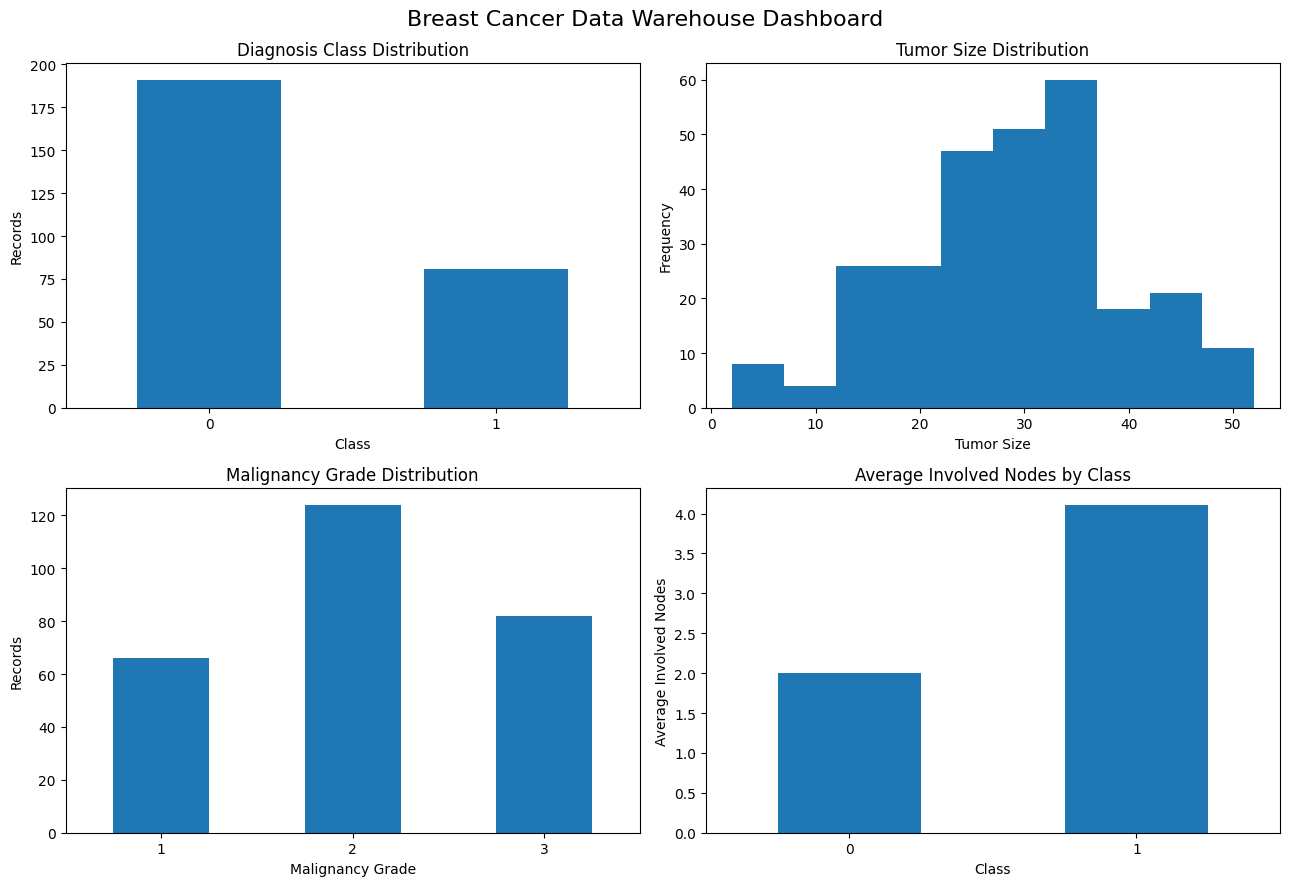

In [5]:

# Step 10.4: Dashboard Layout and KPI Metrics

import matplotlib.pyplot as plt

# Summary metrics
total_records = len(dashboard_df)
class_0_count = (dashboard_df["Class"] == 0).sum()
class_1_count = (dashboard_df["Class"] == 1).sum()
avg_tumor_size = dashboard_df["Tumor_Size"].mean()
avg_inv_nodes = dashboard_df["Inv_Nodes"].mean()

# Display KPI cards
display(widgets.HTML(f"""
<div style="display:flex; flex-wrap:wrap; gap:12px; font-family:Arial;">
  <div style="padding:18px; border:1px solid #888; border-radius:10px; min-width:130px;">
    <h3>Total Records</h3><h2>{total_records}</h2>
  </div>
  <div style="padding:18px; border:1px solid #888; border-radius:10px; min-width:130px;">
    <h3>Class 0</h3><h2>{class_0_count}</h2>
  </div>
  <div style="padding:18px; border:1px solid #888; border-radius:10px; min-width:130px;">
    <h3>Class 1</h3><h2>{class_1_count}</h2>
  </div>
  <div style="padding:18px; border:1px solid #888; border-radius:10px; min-width:160px;">
    <h3>Avg Tumor Size</h3><h2>{avg_tumor_size:.2f}</h2>
  </div>
  <div style="padding:18px; border:1px solid #888; border-radius:10px; min-width:160px;">
    <h3>Avg Involved Nodes</h3><h2>{avg_inv_nodes:.2f}</h2>
  </div>
</div>
"""))

# Create a 2x2 dashboard chart layout
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Chart 1: Diagnosis distribution
dashboard_df["Class"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0, 0], title="Diagnosis Class Distribution"
)
axes[0, 0].set_xlabel("Class")
axes[0, 0].set_ylabel("Records")
axes[0, 0].tick_params(axis="x", rotation=0)

# Chart 2: Tumor size distribution
axes[0, 1].hist(dashboard_df["Tumor_Size"], bins=10)
axes[0, 1].set_title("Tumor Size Distribution")
axes[0, 1].set_xlabel("Tumor Size")
axes[0, 1].set_ylabel("Frequency")

# Chart 3: Malignancy grade
dashboard_df["Deg_Malig"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1, 0], title="Malignancy Grade Distribution"
)
axes[1, 0].set_xlabel("Malignancy Grade")
axes[1, 0].set_ylabel("Records")
axes[1, 0].tick_params(axis="x", rotation=0)

# Chart 4: Average involved nodes by class
dashboard_df.groupby("Class")["Inv_Nodes"].mean().plot(
    kind="bar", ax=axes[1, 1], title="Average Involved Nodes by Class"
)
axes[1, 1].set_xlabel("Class")
axes[1, 1].set_ylabel("Average Involved Nodes")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.suptitle("Breast Cancer Data Warehouse Dashboard", fontsize=16)
plt.tight_layout()
plt.show()


In [6]:
from pathlib import Path
import pandas as pd

# Create output folder
output_dir = Path("../06_Dashboard_Output")
output_dir.mkdir(parents=True, exist_ok=True)

# Generate dashboard summary
summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Class 0 Records",
        "Class 1 Records",
        "Average Tumor Size",
        "Average Involved Nodes"
    ],
    "Value": [
        len(dashboard_df),
        int((dashboard_df["Class"] == 0).sum()),
        int((dashboard_df["Class"] == 1).sum()),
        round(dashboard_df["Tumor_Size"].mean(), 2),
        round(dashboard_df["Inv_Nodes"].mean(), 2)
    ]
})

# Save summary
summary_path = output_dir / "dashboard_summary.csv"
summary.to_csv(summary_path, index=False)

print("Dashboard summary saved successfully!")
print("File:", summary_path.resolve())
display(summary)

Dashboard summary saved successfully!
File: C:\Users\WINDOWS 11\Desktop\Breast_Cancer_Project\06_Dashboard_Output\dashboard_summary.csv


,Metric,Value
0,Total Records,272.00
1,Class 0 Records,191.00
2,Class 1 Records,81.00
3,Average Tumor Size,26.60
4,Average Involved Nodes,2.63
